Подготовка среды

In [1]:
%%writefile lab07_lib.py

# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab07_lib.py


A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'dense', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
psnr     A=  23.119 s= 0.308 B=  22.880 d=  -0.239 |d|/s=   0.78 2s=нет
gap      A=   0.023 s= 0.004 B=   0.111 d=  +0.088 |d|/s=  19.60 2s=да
params   A= 101.035 s= 0.000 B=1580.552 d=+1479.517 |d|/s=    inf 2s=да
seconds  A=   1.747 s= 0.086 B=   1.184 d=  -0.563 |d|/s=   6.52 2s=да
эталон «средняя картинка», PSNR на тесте: 16.763
d=1: PSNR = 19.60 дБ (по seed: 19.63, 19.66, 19.51)
d=2: PSNR = 21.43 дБ (по seed: 21.42, 21.54, 21.34)
d=3: PSNR = 22.71 дБ (по seed: 22.45, 22.33, 23.34)
d=4: PSNR = 23.26 дБ (по seed: 23.33, 23.29, 23.16)
d=8: PSNR = 23.18 дБ (по seed: 23.34, 23.52, 22.69)


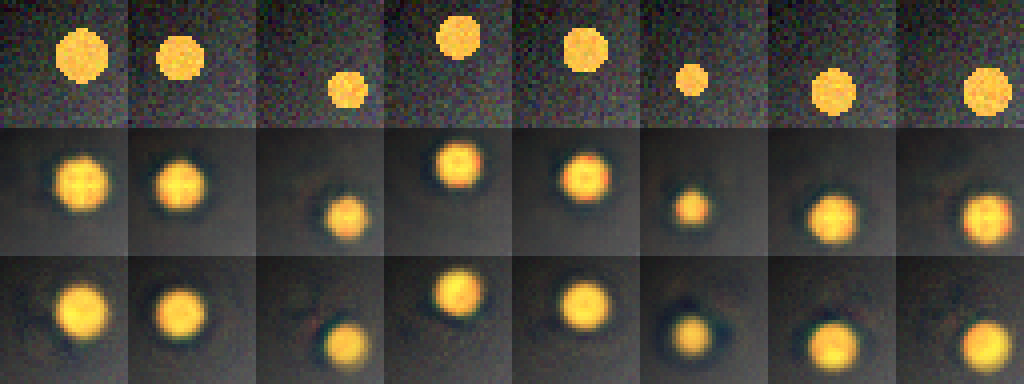

In [3]:
# ЛР 7. Демонстрационный вариант 1: набор «диск», фактор «размер латентного вектора 8 → 2».
import numpy as np
import lab07_lib as L

N = 15
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

# Серия из пяти seed: метрики режимов A и B
result = L.variant_summary(N)
for name, a, s, b, d, q, sig in result["rows"]:
    print(f"{name:8s} A={a:8.3f} s={s:6.3f} B={b:8.3f} d={d:+8.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

# Тривиальный эталон: средняя картинка обучающей выборки, одинаковая для всех входов
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(L.psnr_images(mean_image, Xte), 3))

# Диагностика: PSNR в зависимости от размера латентного вектора (seed 101, 102, 103)
for d in (1, 2, 3, 4, 8):
    vals = [L.run(L.KINDS[c], dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

# Лист сравнения comparison.png: оригиналы, реконструкции режима A и режима B (seed 101, первые 8 тестовых сцен)
from PIL import Image
rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet


In [6]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [7]:
import torch
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

torch: 2.11.0+cu130 | CUDA: True


Вывод режимов A и B

In [8]:
import lab07_lib as L

N = 15
c, k = (N - 1) // 6, (N - 1) % 6
print("набор:", L.KINDS[c], "| фактор:", L.FACTORS[k])
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

набор: disc_noise | фактор: arch_conv_to_dense
A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'dense', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}


Выполнение эксперимента

In [9]:
res = L.variant_summary(15)

print("Вариант", res["variant"], "| набор", res["ctx"], "| фактор", res["factor"])
print(f"{'метрика':10s} {'A':>10s} {'s':>10s} {'B':>10s} {'Δ':>10s} {'|Δ|/s':>8s}  |Δ|>2s")
for m, a, s, b, d, ratio, sig in res["rows"]:
    print(f"{m:10s} {a:10.4f} {s:10.4f} {b:10.4f} {d:+10.4f} {ratio:8.2f}  {sig}")

Вариант 15 | набор 3 | фактор arch_conv_to_dense
метрика             A          s          B          Δ    |Δ|/s  |Δ|>2s
psnr          23.1049     0.3092    22.8802    -0.2247     0.73  False
gap            0.0225     0.0059     0.1114    +0.0889    15.13  True
params       101.0350     0.0000  1580.5520 +1479.5170      inf  True
seconds        1.7248     0.0817     1.1171    -0.6078     7.44  True


Вычисление эталона "средняя картинка"

In [10]:
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
psnr_mean = L.psnr_images(mean_image, Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(psnr_mean, 3), "дБ")

эталон «средняя картинка», PSNR на тесте: 16.763 дБ


Диагностика по размеру d

In [11]:
for d in (1, 2, 3, 4, 8):
    vals = [L.run(L.KINDS[c], dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    print(f"d={d}: PSNR = {np.mean(vals):.2f} dB  (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

d=1: PSNR = 19.64 dB  (по seed: 19.66, 19.71, 19.55)
d=2: PSNR = 21.44 dB  (по seed: 21.43, 21.54, 21.33)
d=3: PSNR = 22.71 dB  (по seed: 22.43, 22.37, 23.34)
d=4: PSNR = 23.17 dB  (по seed: 23.24, 23.16, 23.10)
d=8: PSNR = 23.15 dB  (по seed: 23.35, 23.44, 22.67)


Построение comparison.png

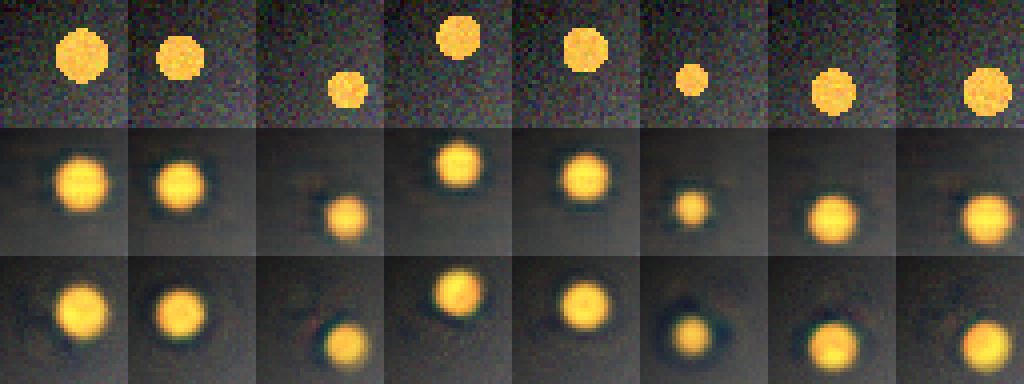

In [12]:
from PIL import Image
import numpy as np

rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))

grid = np.concatenate(
    [np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows],
    axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize(
    (8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet

Классификация по допуску

In [13]:
TOL = {"psnr": 1.0, "gap": 0.1, "seconds": 0.20}
def classify(m, a, b):
    if m == "params":
        return "—"
    if m == "seconds":
        rel = (b - a) / a
        return "быстрее" if rel < -TOL[m] else ("медленнее" if rel > TOL[m] else "нейтрально")
    return "лучше" if b - a >  TOL[m] else ("хуже" if b - a < -TOL[m] else "нейтрально")

print(f"{'метрика':10s} {'A':>8s} {'B':>8s} {'Δ':>8s} {'2s':>5s} {'класс':>12s}")
for m, a, s, b, d, ratio, sig in res["rows"]:
    print(f"{m:10s} {a:8.3f} {b:8.3f} {d:+8.3f} {str(sig):>5s} {classify(m,a,b):>12s}")

метрика           A        B        Δ    2s        класс
psnr         23.105   22.880   -0.225 False   нейтрально
gap           0.023    0.111   +0.089  True   нейтрально
params      101.035 1580.552 +1479.517  True            —
seconds       1.725    1.117   -0.608  True      быстрее
